In [3]:
import dask.dataframe as dd
import h5py
import os

# import trenchripper.trenchripper as tr
import trenchripper as tr
from dask.distributed import wait

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

In [31]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=50,
    n_workers_min=20,
    memory="4GB",
    working_directory= dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

50m
1:00:00


In [2]:
# Experiment paths
headpath = '/home/lag36/scratch/lag36/'
suffix = '/Growth_Division/lineage/'
lineage_paths = {'lLAG08_1': headpath + '/2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/' + suffix,
                 'lLAG10_2': headpath + '/2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14/' + suffix,
                 'lLAG08_5': headpath + '/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/' + suffix,
                 'lLAG08_9': headpath + '/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/' + suffix,
}

# Kymograph metadata paths
suffix = '/Growth_Division/kymograph/metadata/'
kymograph_paths = {'lLAG08_1': headpath + '/2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/' + suffix,
                   'lLAG10_2': headpath + '/2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14/' + suffix,
                   'lLAG08_5': headpath + '/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/' + suffix,
                   'lLAG08_9': headpath + '/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/' + suffix,}

# Time shifts
time_shifts_hours = {'lLAG08_1': 2,
                    'lLAG10_2': 1,
                    'lLAG08_5': 0,
                    'lLAG08_9': 0}

# imaging interval
IMAGING_INTERVAL = 10  # minutes
N_FRAMES_PER_HOUR = 60 // IMAGING_INTERVAL

time_shift_n_timepoints = {
    key: int(value * N_FRAMES_PER_HOUR) for key, value in time_shifts_hours.items()
}

time_shift_seconds = {
    key: value * 3600 for key, value in time_shifts_hours.items()
}

print("Time shifts in hours:", time_shifts_hours)
print("Time shifts in timepoints:", time_shift_n_timepoints)
print("Time shifts in seconds:", time_shift_seconds)

Time shifts in hours: {'lLAG08_1': 2, 'lLAG10_2': 1, 'lLAG08_5': 0, 'lLAG08_9': 0}
Time shifts in timepoints: {'lLAG08_1': 12, 'lLAG10_2': 6, 'lLAG08_5': 0, 'lLAG08_9': 0}
Time shifts in seconds: {'lLAG08_1': 7200, 'lLAG10_2': 3600, 'lLAG08_5': 0, 'lLAG08_9': 0}


I need to find out how Daniel reads parquet file, how he saves them, and how he makes copies. Is it just changing the directory name?
- Also: How does he open the lineage dataframe?

In [33]:
# Load the kymograph metadata dds
kymo_dds = {key: dd.read_parquet(path) for key, path in kymograph_paths.items()}

# Load the lineage dds
lineage_dds = {key: dd.read_parquet(path, engine='pyarrow') for key, path in lineage_paths.items()}

In [34]:
print(kymo_dds['lLAG08_1'].columns) # offset both 'timepoints' and 'time (s)'
print(lineage_dds['lLAG08_1'].columns) # offset 'timepoints' only
# # NOTE: I worry about the 'Trenchid Timepoint Index' in both
# # NOTE: I will add new columns to keep the original timepoints and time (s) in the lineage dds

Index(['fov', 'row', 'trench', 'timepoints', 'time (s)', 'lane orientation',
       'y (local)', 'x (local)', 'y (global)', 'x (global)', 'Global Row',
       'File Index', 'File Trench Index', 'File Parquet Index', 'trenchid',
       'Trenchid Timepoint Index'],
      dtype='object')
Index(['File Index', 'File Trench Index', 'timepoints', 'CellID', 'fov', 'row',
       'trench', 'trenchid', 'Segment Index', 'Global CellID',
       'lane orientation', 'Trench Score', 'Mother CellID',
       'Daughter CellID 1', 'Daughter CellID 2', 'Sister CellID', 'Centroid X',
       'Centroid Y', 'Cell X (local)', 'Cell Y (local)', 'area', 'Length',
       'Width', 'Volume', 'Surface Area', 'mCherry mean_intensity', 'Mother',
       'Kymograph File Parquet Index', 'Kymograph FOV Parquet Index',
       'Trenchid Timepoint Index', 'FOV Parquet Index'],
      dtype='object')


In [ ]:
dask_cont

In [35]:
lineage_dds_shifted = {
    key: lineage_dds[key]
          .assign(timepoints_pre_shift = lambda df_:df_['timepoints'],
                  timepoints = lambda df_: df_['timepoints'] + time_shift_n_timepoints[key])
    for key in kymo_dds.keys()
}

kymo_dds_shifted = {
    key: kymo_dds[key]
          .assign(timepoints_pre_shift = lambda df_:df_['timepoints'],
                  timepoints = lambda df_: df_['timepoints'] + time_shift_n_timepoints[key])
          .assign(**{'time (s)_pre_shift': lambda df_: df_['time (s)'],
                   'time (s)': lambda df_: df_['time (s)'] + time_shift_seconds[key]})
    for key in kymo_dds.keys()
}

In [36]:
# # Validate the shifts by printing the tail for each dataset
# for key in kymo_dds_shifted.keys():
#     print(f"Dataset: {key}")
#     print("Lineage tail:")
#     print(lineage_dds_shifted[key][['timepoints', 'timepoints_pre_shift']].tail())
#     print("\nKymograph tail:")
#     print(kymo_dds_shifted[key][['timepoints', 'timepoints_pre_shift', 'time (s)', 'time (s)_pre_shift']].tail())
#     print("\n")

In [37]:
# Get the timepoints of the first fov
for key in kymo_dds_shifted.keys():
    print(f"Dataset: {key}")
    print("Lineage first fov:")
    print(lineage_dds_shifted[key].loc[lineage_dds_shifted[key]['fov'] == 0, ['timepoints', 'timepoints_pre_shift']].groupby('timepoints').first().head())
    print("\nKymograph first fov:")
    print(kymo_dds_shifted[key].loc[kymo_dds_shifted[key]['fov'] == 0, ['timepoints', 'timepoints_pre_shift', 'time (s)', 'time (s)_pre_shift']
                                    ].groupby('timepoints').first().head())

Dataset: lLAG08_1
Lineage first fov:
            timepoints_pre_shift
timepoints                      
12                             0
13                             1
14                             2
15                             3
16                             4

Kymograph first fov:
            timepoints_pre_shift     time (s)  time (s)_pre_shift
timepoints                                                       
12                             0  7200.864806            0.864806
13                             1  7800.797509          600.797509
14                             2  8400.784231         1200.784231
15                             3  9000.708459         1800.708459
16                             4  9600.727490         2400.727490
Dataset: lLAG10_2
Lineage first fov:
            timepoints_pre_shift
timepoints                      
6                              0
7                              1
8                              2
9                              3
10           

In [39]:
# Same as above but for the tail
for key in kymo_dds_shifted.keys():
    print(f"Dataset: {key}")
    print("Lineage last fov:")
    print(lineage_dds_shifted[key].loc[lineage_dds_shifted[key]['fov'] == 0, ['timepoints', 'timepoints_pre_shift']].groupby('timepoints').first().tail())
    print("\nKymograph last fov:")
    print(kymo_dds_shifted[key].loc[kymo_dds_shifted[key]['fov'] == 0, ['timepoints', 'timepoints_pre_shift', 'time (s)', 'time (s)_pre_shift']
                                    ].groupby('timepoints').first().tail())

Dataset: lLAG08_1
Lineage last fov:
            timepoints_pre_shift
timepoints                      
68                            56
69                            57
70                            58
71                            59
72                            60

Kymograph last fov:
            timepoints_pre_shift      time (s)  time (s)_pre_shift
timepoints                                                        
68                            56  40800.199977        33600.199977
69                            57  41400.023308        34200.023308
70                            58  42000.077818        34800.077818
71                            59  42600.029102        35400.029102
72                            60  43199.985495        35999.985495
Dataset: lLAG10_2
Lineage last fov:
            timepoints_pre_shift
timepoints                      
68                            62
69                            63
70                            64
71                            65
72       

In [40]:
new_kymo_paths = {
    key: path.replace('metadata', 'metadata_shifted') for key, path in kymograph_paths.items()
}

In [42]:
headpath

'/home/lag36/scratch/lag36/'

In [41]:
new_kymo_paths

{'lLAG08_1': '/home/lag36/scratch/lag36//2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14//Growth_Division/kymograph/metadata_shifted/',
 'lLAG10_2': '/home/lag36/scratch/lag36//2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14//Growth_Division/kymograph/metadata_shifted/',
 'lLAG08_5': '/home/lag36/scratch/lag36//2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch//Growth_Division/kymograph/metadata_shifted/',
 'lLAG08_9': '/home/lag36/scratch/lag36//2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch//Growth_Division/kymograph/metadata_shifted/'}

In [16]:
# Experiment paths
headpath = '/home/lag36/scratch/lag36/'
suffix = '/Growth_Division/lineage_shifted/'
lineage_paths_shifted = {'lLAG08_1': headpath + '/2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/' + suffix,
                 'lLAG10_2': headpath + '/2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14/' + suffix,
                 'lLAG08_5': headpath + '/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/' + suffix,
                 'lLAG08_9': headpath + '/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/' + suffix,
}

# Kymograph metadata paths
suffix = '/Growth_Division/kymograph/metadata_shifted/'
kymograph_paths_shifted = {'lLAG08_1': headpath + '/2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/' + suffix,
                   'lLAG10_2': headpath + '/2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14/' + suffix,
                   'lLAG08_5': headpath + '/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/' + suffix,
                   'lLAG08_9': headpath + '/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/' + suffix,}

In [47]:
# Save the shifted dds to disk
for key in kymo_dds_shifted.keys():
    dd.to_parquet(kymo_dds_shifted[key],
                  kymograph_paths_shifted[key],
                  engine='pyarrow',
                  compression='gzip',
                  write_metadata_file=True,
                  overwrite=True)

In [48]:
for key in lineage_dds_shifted.keys():
    dd.to_parquet(lineage_dds_shifted[key],
                  lineage_paths_shifted[key],
                  engine='fastparquet',
                  compression='gzip',
                  write_metadata_file=True,
                  overwrite=True)

In [49]:
dask_controller.shutdown()

Done.


2025-05-29 21:39:46,612 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [8]:
## NEW PATHS FOR OLD DATA
# Experiment paths
headpath = '/home/lag36/scratch/lag36/'
suffix = '/Growth_Division/lineage_time_nonshifted/'
lineage_paths_nonshifted_final = {'lLAG08_1': headpath + '/2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/' + suffix,
                 'lLAG10_2': headpath + '/2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14/' + suffix,
                 'lLAG08_5': headpath + '/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/' + suffix,
                 'lLAG08_9': headpath + '/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/' + suffix,
}

# Kymograph metadata paths
suffix = '/Growth_Division/kymograph/metadata_time_nonshifted/'
kymograph_paths_nonshifted_final = {'lLAG08_1': headpath + '/2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/' + suffix,
                   'lLAG10_2': headpath + '/2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14/' + suffix,
                   'lLAG08_5': headpath + '/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/' + suffix,
                   'lLAG08_9': headpath + '/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/' + suffix,}

In [15]:
## NEW PATHS
# Experiment paths
lineage_paths_shifted_final = lineage_paths

# Kymograph metadata paths
kymograph_paths_shifted_final = kymograph_paths

In [11]:
# Testing renaming
os.rename('/home/lag36/test/lineage', '/home/lag36/test/lineage_shifted')

In [13]:
# Change folder names for the unshifted data
for key in lineage_paths_nonshifted_final.keys():
    old_lineage_path = lineage_paths[key]
    new_lineage_path = lineage_paths_nonshifted_final[key]
    os.rename(old_lineage_path, new_lineage_path)

    old_kymo_path = kymograph_paths[key]
    new_kymo_path = kymograph_paths_nonshifted_final[key]
    os.rename(old_kymo_path, new_kymo_path)

In [20]:
# Change folder names for the shifted data
for key in lineage_paths_shifted_final.keys():
    old_lineage_path = lineage_paths_shifted[key]
    new_lineage_path = lineage_paths_shifted_final[key]
    os.rename(old_lineage_path, new_lineage_path)
    print(f"Renaming {old_lineage_path} to {new_lineage_path}")
    old_kymo_path = kymograph_paths_shifted[key]
    new_kymo_path = kymograph_paths_shifted_final[key]
    os.rename(old_kymo_path, new_kymo_path)
    print(f"Renaming {old_kymo_path} to {new_kymo_path}")

Renaming /home/lag36/scratch/lag36//2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14//Growth_Division/lineage_shifted/ to /home/lag36/scratch/lag36//2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14//Growth_Division/lineage/
Renaming /home/lag36/scratch/lag36//2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14//Growth_Division/kymograph/metadata_shifted/ to /home/lag36/scratch/lag36//2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14//Growth_Division/kymograph/metadata/
Renaming /home/lag36/scratch/lag36//2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14//Growth_Division/lineage_shifted/ to /home/lag36/scratch/lag36//2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14//Growth_Division/lineage/
Renaming /home/lag36/scratch/lag36//2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14//Growth_Division/kymograph/metadata_shifted/ to /home/lag36/scratch/lag36//2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Ru

### Save kymos as tiff for cellpose check

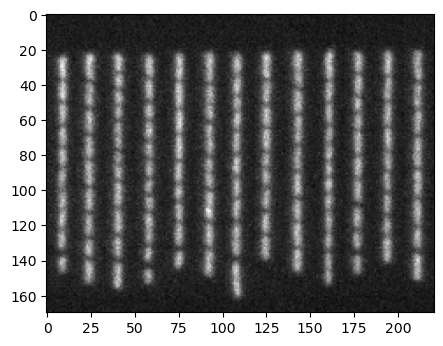

In [145]:
channels = ['mCherry']
kymo_index = 70
trench_index = 87
indices = np.arange(0, 73 ,6)
cmap = 'gray'

file_path = headpath + '/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/' + f'Growth_Division/kymograph/kymograph_{kymo_index}.hdf5'

with h5py.File(file_path, "r") as infile:
        # print(infile['mCherry'].shape)
        # indices = list(range(0, 1, 1))

        for ch in channels:
            img = infile[ch][trench_index][indices[0]]
            for ind in indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            _= plt.figure(figsize=(5, 20))
            _ = plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate kymo and trench index
            # _= plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
            _=plt.show()
            _=plt.close()

In [59]:
img.shape

(170, 221)

In [142]:
# Save numpy array as tif
def save_as_tif(array, filename):
    import tifffile as tiff
    tiff.imwrite(filename, array, photometric='minisblack')

# Example usage
save_as_tif(img, './kymograph_image_long_weird.tif')